## Bulk Differential Expression Analysis

1. Libraries Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import yaml
from importlib.metadata import version

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

print("PyDESeq2 version:", version("pydeseq2"))

PyDESeq2 version: 0.4.10


2. Set Paths

In [2]:
# Find the project folder
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "config.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

# Read the team config file
with open(PROJECT_ROOT / "config.yaml", encoding="utf-8") as file:
    config = yaml.safe_load(file)

# Input files
COUNT_FILE = PROJECT_ROOT / config["inputs"]["counts"]
METADATA_FILE = PROJECT_ROOT / config["inputs"]["metadata"]

# Output folders
TABLES_DIR = PROJECT_ROOT / config["differential_expression"]["tables"]
FIGURES_DIR = PROJECT_ROOT / config["differential_expression"]["figures"]
DE_OUTPUT = PROJECT_ROOT / config["inputs"]["differential_expression_results"]
ALPHA = config["differential_expression"]["alpha"]

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Count file exists:", COUNT_FILE.exists())
print("Metadata file exists:", METADATA_FILE.exists())
print("Significance level:", ALPHA)

Count file exists: True
Metadata file exists: True
Significance level: 0.05


3. Load Input Data

In [3]:
# Read the input files
counts_raw = pd.read_csv(COUNT_FILE, sep="\t")
metadata_raw = pd.read_csv(METADATA_FILE, sep="\t")

# Show the first rows
display(counts_raw.head())
display(metadata_raw.head())

,gene_id,ERR1629982,ERR1629983,ERR1629984,ERR1629985,ERR1629986,ERR1629987,ERR1629988
0,ENSG00000290825.1,0,0,0,0,0,0,0
1,ENSG00000223972.6,0,0,0,0,0,0,0
2,ENSG00000227232.5,40,18,13,29,15,24,19
3,ENSG00000278267.1,10,9,3,6,8,7,5
4,ENSG00000243485.5,0,0,0,0,0,0,0


,sample_id,donor_id,source_donor_id,condition,sex,age,bmi,hba1c
0,ERR1629982,T2D1,HP1504101T2D,T2D,male,57,24.0,7.00%
1,ERR1629983,H6,HP1504901,Non-diabetic,male,23,21.5,5.50%
2,ERR1629984,H3,HP1506401,Non-diabetic,female,48,35.0,5.70%
3,ERR1629985,H4,HP1507101,Non-diabetic,male,22,32.9,5.40%
4,ERR1629986,T2D2,HP1508501T2D,T2D,female,37,39.6,7.30%


4. Check Data Structure

In [4]:
print("Count matrix shape:", counts_raw.shape)

print("\nCount matrix columns:")
print(counts_raw.columns.tolist()[:10])

print("\nMetadata columns:")
print(metadata_raw.columns.tolist())

print("\nMetadata preview:")
display(metadata_raw.head())

Count matrix shape: (62754, 8)

Count matrix columns:
['gene_id', 'ERR1629982', 'ERR1629983', 'ERR1629984', 'ERR1629985', 'ERR1629986', 'ERR1629987', 'ERR1629988']

Metadata columns:
['sample_id', 'donor_id', 'source_donor_id', 'condition', 'sex', 'age', 'bmi', 'hba1c']

Metadata preview:


,sample_id,donor_id,source_donor_id,condition,sex,age,bmi,hba1c
0,ERR1629982,T2D1,HP1504101T2D,T2D,male,57,24.0,7.00%
1,ERR1629983,H6,HP1504901,Non-diabetic,male,23,21.5,5.50%
2,ERR1629984,H3,HP1506401,Non-diabetic,female,48,35.0,5.70%
3,ERR1629985,H4,HP1507101,Non-diabetic,male,22,32.9,5.40%
4,ERR1629986,T2D2,HP1508501T2D,T2D,female,37,39.6,7.30%


5. Prepare Count Matrix and Metadata

In [5]:
# Metadata column names
SAMPLE_COL = 'sample_id'
CONDITION_COL = 'condition'	

# Prepare count matrix
counts = counts_raw.set_index(counts_raw.columns[0]).T

# Prepare metadata
metadata = metadata_raw[[SAMPLE_COL, CONDITION_COL]].copy()
metadata = metadata.set_index(SAMPLE_COL)
metadata = metadata.rename(columns={CONDITION_COL: "condition"})

# Clean sample names
counts.index = counts.index.astype(str).str.strip()
metadata.index = metadata.index.astype(str).str.strip()

# Clean group labels
metadata["condition"] = metadata["condition"].astype(str).str.strip()

print("Counts shape:", counts.shape)
print("\nSample groups:")
print(metadata["condition"].value_counts())

Counts shape: (7, 62754)

Sample groups:
condition
T2D             4
Non-diabetic    3
Name: count, dtype: int64


6. Validate Samples and Counts

In [6]:
# Check sample names
print("Samples in counts:", len(counts.index))
print("Samples in metadata:", len(metadata.index))

print("\nSamples only in counts:")
print(sorted(set(counts.index) - set(metadata.index)))

print("\nSamples only in metadata:")
print(sorted(set(metadata.index) - set(counts.index)))

Samples in counts: 7
Samples in metadata: 7

Samples only in counts:
[]

Samples only in metadata:
[]


In [7]:
# Match sample order
if set(counts.index) != set(metadata.index):
    raise ValueError("Sample IDs do not match. Check the sample names.")

metadata = metadata.loc[counts.index]

# Check count values
counts = counts.apply(pd.to_numeric, errors="raise")

if (counts < 0).any().any():
    raise ValueError("Negative counts were found.")

if not np.all(np.isclose(counts.to_numpy(), np.round(counts.to_numpy()))):
    raise ValueError("The count matrix contains non-integer values.")

counts = counts.astype(int)

print("Sample IDs match.")
print("Count values are valid.")

Sample IDs match.
Count values are valid.


7. Filter Genes

In [8]:
# Remove genes with zero counts in all samples
before_filtering = counts.shape[1]

counts = counts.loc[:, counts.sum(axis=0) > 0]

after_filtering = counts.shape[1]

print("Genes before filtering:", before_filtering)
print("Genes after filtering:", after_filtering)
print("Genes removed:", before_filtering - after_filtering)

Genes before filtering: 62754
Genes after filtering: 33432
Genes removed: 29322


8. Final Data Check

In [9]:
# Check the count matrix
print("Count matrix shape:", counts.shape)
print("Missing values:", counts.isna().sum().sum())
print("Negative values:", (counts < 0).sum().sum())
print("Duplicated sample IDs:", counts.index.duplicated().sum())
print("Duplicated gene IDs:", counts.columns.duplicated().sum())

Count matrix shape: (7, 33432)
Missing values: 0
Negative values: 0
Duplicated sample IDs: 0
Duplicated gene IDs: 0


In [10]:
# Check sample metadata
print("Metadata shape:", metadata.shape)

display(metadata.head())

print("Metadata columns:")
print(metadata.columns.tolist())

print("Count matrix sample IDs:")
print(counts.index.tolist())

print("Metadata sample IDs:")
print(metadata.index.tolist())

Metadata shape: (7, 1)


,condition
ERR1629982,T2D
ERR1629983,Non-diabetic
ERR1629984,Non-diabetic
ERR1629985,Non-diabetic
ERR1629986,T2D


Metadata columns:
['condition']
Count matrix sample IDs:
['ERR1629982', 'ERR1629983', 'ERR1629984', 'ERR1629985', 'ERR1629986', 'ERR1629987', 'ERR1629988']
Metadata sample IDs:
['ERR1629982', 'ERR1629983', 'ERR1629984', 'ERR1629985', 'ERR1629986', 'ERR1629987', 'ERR1629988']


9. Define the Comparison

In [11]:
# Check the available metadata columns
print(metadata.columns.tolist())

['condition']


In [12]:
# Update these values to match the metadata
condition_col = 'condition'
t2d_label = 'T2D'
control_label = 'Non-diabetic'

print(metadata[condition_col].value_counts())

condition
T2D             4
Non-diabetic    3
Name: count, dtype: int64


10. Differential Expression Analysis

In [13]:
# Create the DESeq2 dataset
dds = DeseqDataSet(
    counts=counts,
    metadata=metadata,
    design_factors=condition_col,
    n_cpus=2
)

# Run the model
dds.deseq2()

Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 15.92 seconds.

Fitting dispersion trend curve...
... done in 0.85 seconds.

Fitting MAP dispersions...
... done in 20.14 seconds.

Fitting LFCs...
... done in 13.94 seconds.

Calculating cook's distance...
... done in 0.04 seconds.

Replacing 0 outlier genes.



In [14]:
# Compare T2D against non-diabetic samples
stat_res = DeseqStats(
    dds,
    contrast=[condition_col, t2d_label, control_label],
    alpha=0.05
)

stat_res.summary()

results = stat_res.results_df.copy()

display(results.head())

Running Wald tests...


... done in 6.88 seconds.



Log2 fold change & Wald test p-value: condition T2D vs Non-diabetic
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_id                                                                      
ENSG00000227232.5  23.089821        0.543811  0.547949  0.992449  0.320979   
ENSG00000278267.1   6.881551        0.508027  0.708373  0.717173  0.473267   
ENSG00000238009.6   1.153895        0.505383  1.603992  0.315078  0.752702   
ENSG00000268903.1  19.562427        0.693730  0.740279  0.937119  0.348698   
ENSG00000269981.1  14.007763        0.202276  0.917064  0.220569  0.825428   
...                      ...             ...       ...       ...       ...   
ENSG00000278673.1   1.393773        1.686569  1.805982  0.933879  0.350366   
ENSG00000273554.4   0.112793        0.901017  4.200335  0.214511  0.830149   
ENSG00000276700.1   0.679573        2.785514  3.697595  0.753331  0.451251   
ENSG00000278817.1  17.721232       -0.077330  0.606154 -0.127575  0.898485

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_id,,,,,,
ENSG00000227232.5,23.089821,0.543811,0.547949,0.992449,0.320979,0.831170
ENSG00000278267.1,6.881551,0.508027,0.708373,0.717173,0.473267,NaN
ENSG00000238009.6,1.153895,0.505383,1.603992,0.315078,0.752702,NaN
ENSG00000268903.1,19.562427,0.693730,0.740279,0.937119,0.348698,0.841396
ENSG00000269981.1,14.007763,0.202276,0.917064,0.220569,0.825428,0.976299


11. Extract and Save Results

In [ ]:
# Save the full results table
DE_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(DE_OUTPUT, index=True, index_label="gene_id")

print("Full results saved successfully.")
print("Number of genes:", len(results))

12. Select Significant Genes

In [16]:
# Select genes with adjusted p-value below the cutoff
significant = results[results["padj"] < ALPHA].copy()

# Separate upregulated and downregulated genes
upregulated = significant[significant["log2FoldChange"] > 0].copy()
downregulated = significant[significant["log2FoldChange"] < 0].copy()

# Save the tables
significant.to_csv(TABLES_DIR / "significant_genes.csv", index=True, index_label="gene_id")
upregulated.to_csv(TABLES_DIR / "upregulated_genes.csv", index=True, index_label="gene_id")
downregulated.to_csv(TABLES_DIR / "downregulated_genes.csv", index=True, index_label="gene_id")

print("Significant genes:", len(significant))
print("Upregulated genes:", len(upregulated))
print("Downregulated genes:", len(downregulated))

Significant genes: 133
Upregulated genes: 105
Downregulated genes: 28


13. Volcano Plot

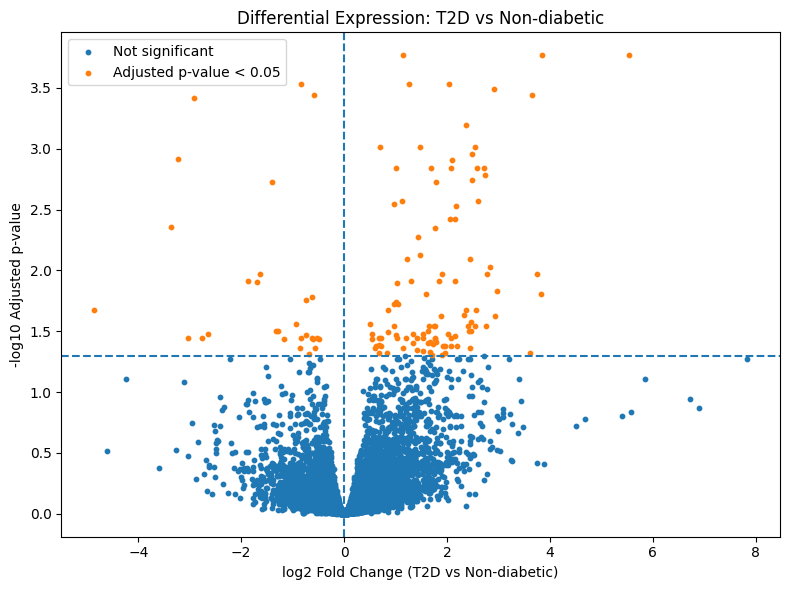

In [17]:
# Prepare data for the plot
plot_data = results.dropna(subset=["log2FoldChange", "padj"]).copy()
plot_data["neg_log10_padj"] = -np.log10(plot_data["padj"].clip(lower=1e-300))

significant_mask = plot_data["padj"] < ALPHA

# Draw the plot
plt.figure(figsize=(8, 6))

plt.scatter(
    plot_data.loc[~significant_mask, "log2FoldChange"],
    plot_data.loc[~significant_mask, "neg_log10_padj"],
    s=10,
    label="Not significant"
)

plt.scatter(
    plot_data.loc[significant_mask, "log2FoldChange"],
    plot_data.loc[significant_mask, "neg_log10_padj"],
    s=10,
    label=f"Adjusted p-value < {ALPHA}"
)

plt.axhline(-np.log10(ALPHA), linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("log2 Fold Change (T2D vs Non-diabetic)")
plt.ylabel("-log10 Adjusted p-value")
plt.title("Differential Expression: T2D vs Non-diabetic")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "volcano_plot.png", dpi=300, bbox_inches="tight")
plt.show()

14. MA Plot

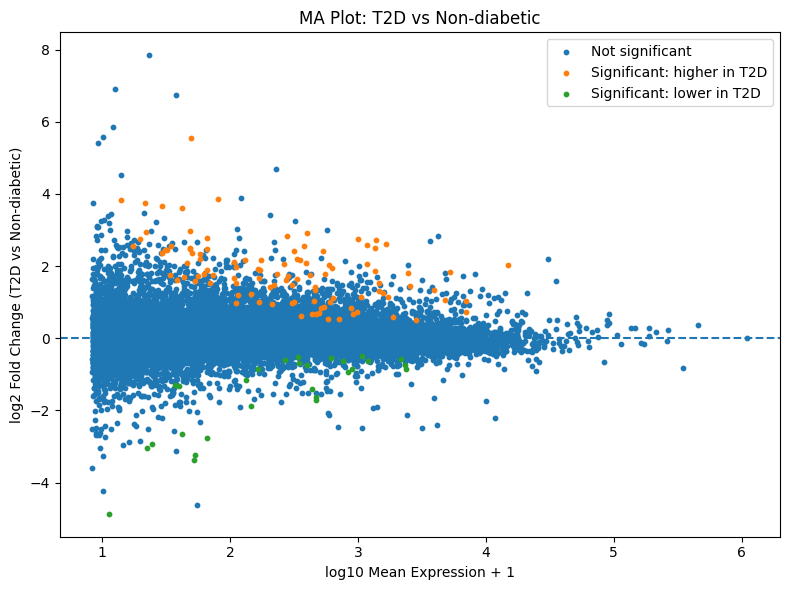

In [18]:
# Prepare data for the MA plot
ma_data = results.dropna(subset=["baseMean", "log2FoldChange", "padj"]).copy()

# Mark significant genes in each direction
sig_up = (ma_data["padj"] < ALPHA) & (ma_data["log2FoldChange"] > 0)
sig_down = (ma_data["padj"] < ALPHA) & (ma_data["log2FoldChange"] < 0)
not_sig = ~(sig_up | sig_down)

# Draw the plot
plt.figure(figsize=(8, 6))

plt.scatter(
    np.log10(ma_data.loc[not_sig, "baseMean"] + 1),
    ma_data.loc[not_sig, "log2FoldChange"],
    s=10,
    label="Not significant"
)

plt.scatter(
    np.log10(ma_data.loc[sig_up, "baseMean"] + 1),
    ma_data.loc[sig_up, "log2FoldChange"],
    s=10,
    label="Significant: higher in T2D"
)

plt.scatter(
    np.log10(ma_data.loc[sig_down, "baseMean"] + 1),
    ma_data.loc[sig_down, "log2FoldChange"],
    s=10,
    label="Significant: lower in T2D"
)

plt.axhline(0, linestyle="--")
plt.xlabel("log10 Mean Expression + 1")
plt.ylabel("log2 Fold Change (T2D vs Non-diabetic)")
plt.title("MA Plot: T2D vs Non-diabetic")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "MA_plot.png", dpi=300, bbox_inches="tight")
plt.show()


 15. Summary of Results

In [19]:
# Summarize the results
summary = pd.DataFrame({
    "Metric": [
        "Total genes in results",
        "Significant genes",
        "Upregulated genes",
        "Downregulated genes"
    ],
    "Count": [
        len(results),
        len(significant),
        len(upregulated),
        len(downregulated)
    ]
})

display(summary)
summary.to_csv(TABLES_DIR / "differential_expression_summary.csv", index=False)


,Metric,Count
0,Total genes in results,33432
1,Significant genes,133
2,Upregulated genes,105
3,Downregulated genes,28
